In [ ]:
import pandas as pd
import geopandas as gpd
import numpy as np
from scipy.stats import zscore
from shapely import wkt

# ✅ Relative path - works on anyone's computer!
flood_csv_path = "data/New_York_City_Flood_Vulnerability_Index.csv"
demo_csv_path = "data/NewYork_SVI.csv"

df_flood_raw = pd.read_csv(flood_csv_path)

# We use read_csv because flood data is a CSV with a 'the_geom' column
df_flood_raw = pd.read_csv(flood_csv_path)
df_flood_raw['geometry'] = df_flood_raw['the_geom'].apply(wkt.loads)
gdf_flood = gpd.GeoDataFrame(df_flood_raw, geometry='geometry', crs="EPSG:4326")

df_demo = pd.read_csv(demo_csv_path)

# Clean identifiers
def clean_geoid(column):
    # This removes decimals, spaces, and ensures 11 digits for NYC Census Tracts
    return column.astype(str).str.strip().str.replace('.0', '', regex=False).str.zfill(11)

gdf_flood['GEOID'] = clean_geoid(gdf_flood['GEOID'])
df_demo['FIPS'] = clean_geoid(df_demo['FIPS'])

# Merge and clean data
# Pull RPL_THEME1 (SVI) and EP_POV150 (Poverty)
vulnerability_cols = ['FIPS', 'RPL_THEME1', 'EP_POV150']
master_gdf = gdf_flood.merge(df_demo[vulnerability_cols], left_on='GEOID', right_on='FIPS', how='left')
# Replace 'no data' markers (-999) with NaN, then fill with median
master_gdf['RPL_THEME1'] = master_gdf['RPL_THEME1'].replace([-999, -1], np.nan)
master_gdf['FSHRI'] = pd.to_numeric(master_gdf['FSHRI'], errors='coerce')

master_gdf['RPL_THEME1'] = master_gdf['RPL_THEME1'].fillna(master_gdf['RPL_THEME1'].median())
master_gdf['FSHRI'] = master_gdf['FSHRI'].fillna(master_gdf['FSHRI'].median())

# Calculate Z-Scores (Centered at 0)
master_gdf['svi_z'] = zscore(master_gdf['RPL_THEME1'])
master_gdf['risk_z'] = zscore(master_gdf['FSHRI'])

# Final Weighted Score: 70% Social, 30% Physical Risk
master_gdf['Weighted_Vulnerability'] = (master_gdf['svi_z'] * 0.7) + (master_gdf['risk_z'] * 0.3)

print("--- PHASE 1 SUCCESSFUL ---")
print(f"Total Tracts Analyzed: {len(master_gdf)}")
print(master_gdf[['GEOID', 'Weighted_Vulnerability']].head())

--- PHASE 1 SUCCESSFUL ---
Total Tracts Analyzed: 2209
         GEOID  Weighted_Vulnerability
0  36005008500                1.330832
1  36081008600                0.908714
2  36047058000                0.799915
3  36047053200                0.546487
4  36081004500               -0.131674


In [ ]:
print(f"Total projects in the dataset: {len(gdf_projects)}")

Total projects in the dataset: 10438


In [ ]:
df_projects_raw = pd.concat(all_dfs, axis=0, ignore_index=True)

# NYC projects use HEX/Binary geometry; convert it to geodata for standardization
from shapely import wkb

def safe_load_hex(hex_str):
    try: return wkb.loads(str(hex_str), hex=True)
    except: return None

df_projects_raw['geometry'] = df_projects_raw['geom'].apply(safe_load_hex)
gdf_projects = gpd.GeoDataFrame(df_projects_raw.dropna(subset=['geometry']),
                                geometry='geometry', crs="EPSG:4326")

# Use keyword logic to determine if a project is Preventative or Reconstructive
prevent_kw = 'mitigation|resiliency|adaptation|protection|barrier|tide gate|cloudburst|drainage|green infrastructure'
recon_kw = 'sandy|ida|repair|reconstruct|restore|recovery|damage'

gdf_projects['is_preventative'] = gdf_projects['descript'].str.contains(prevent_kw, case=False, na=False)
gdf_projects['is_reconstructive'] = gdf_projects['descript'].str.contains(recon_kw, case=False, na=False)

def assign_nature(row):
    if row['is_preventative']: return 'Preventative'
    if row['is_reconstructive']: return 'Reconstructive'
    return 'General'

gdf_projects['nature'] = gdf_projects.apply(assign_nature, axis=1)

# Convert both to NYC State Plane (Feet) for accurate buffering
master_projected = master_gdf.to_crs("EPSG:2263")
projects_projected = gdf_projects.to_crs("EPSG:2263")
# Create a 200-meter (656 feet) buffer around project points/lines
projects_projected['geometry'] = projects_projected.buffer(656)

# Join: Which projects intersect which tracts?
joined_data = gpd.sjoin(master_projected, projects_projected, how="left", predicate="intersects")

print(f"Phase 2 Complete: {len(gdf_projects)} projects mapped to {len(master_gdf)} tracts.")

Phase 2 Complete: 10438 projects mapped to 2209 tracts.


In [ ]:
# Calculate Protection score by tract
def calculate_protection(group):
    # Log-scale the budget (plus 1 to avoid log(0))
    budget_val = np.log1p(pd.to_numeric(group['altotal'], errors='coerce').fillna(0).sum())

    # Weight the nature of projects
    counts = group['nature'].value_counts()
    nature_val = (counts.get('Preventative', 0) * 2.0) + \
                 (counts.get('Reconstructive', 0) * 1.0) + \
                 (counts.get('General', 0) * 0.5)

    # Combine Budget and Nature into one Protection Score
    return budget_val + nature_val

# Apply the calculation to joint data
protection_stats = joined_data.groupby('GEOID').apply(calculate_protection).reset_index(name='Raw_Protection')

# Normalize protection scores (0 to 1) so it's comparable to Z-scores
max_p = protection_stats['Raw_Protection'].max()
protection_stats['Normalized_Protection'] = protection_stats['Raw_Protection'] / (max_p if max_p > 0 else 1)

# Merge protection back into our master vulnerability table
final_analysis = master_gdf.merge(protection_stats, on='GEOID', how='left').fillna(0)
# Neglect = (Risk + Poverty) - (Money + Prevention)
# We multiply Protection by 2 to give it equal 'weight' against the Z-scores
final_analysis['Neglect_Score'] = final_analysis['Weighted_Vulnerability'] - (final_analysis['Normalized_Protection'] * 2)
top_neglected = final_analysis.sort_values('Neglect_Score', ascending=False).head(10)

print("NEGLECT INDEX GENERATED")
print("Top 5 Most Under-Protected Neighborhoods (GEOIDs):")
print(top_neglected[['GEOID', 'Weighted_Vulnerability', 'Normalized_Protection', 'Neglect_Score']])

/tmp/ipykernel_20203/2731142819.py:4: RuntimeWarning: invalid value encountered in log1p
  budget_val = np.log1p(pd.to_numeric(group['altotal'], errors='coerce').fillna(0).sum())
/tmp/ipykernel_20203/2731142819.py:4: RuntimeWarning: invalid value encountered in log1p
  budget_val = np.log1p(pd.to_numeric(group['altotal'], errors='coerce').fillna(0).sum())
/tmp/ipykernel_20203/2731142819.py:4: RuntimeWarning: invalid value encountered in log1p
  budget_val = np.log1p(pd.to_numeric(group['altotal'], errors='coerce').fillna(0).sum())


--- PHASE 3 COMPLETE: NEGLECT INDEX GENERATED ---
Top 5 Most Under-Protected Neighborhoods (GEOIDs):
           GEOID  Weighted_Vulnerability  Normalized_Protection  Neglect_Score
346  36081116302                1.278002               0.000000       1.278002
393  36081032700                1.315925               0.053132       1.209661
363  36005005001                1.370062               0.081202       1.207659
405  36081056400                1.180188               0.000000       1.180188
326  36081116700                1.157696               0.000000       1.157696
145  36081044301                1.368493               0.120857       1.126779
158  36047007600                1.319848               0.101760       1.116328
209  36081119100                1.212880               0.048312       1.116256
185  36005040303                1.298402               0.100958       1.096486
411  36005044200                1.292125               0.101663       1.088799


/tmp/ipykernel_20203/2731142819.py:16: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  protection_stats = joined_data.groupby('GEOID').apply(calculate_protection).reset_index(name='Raw_Protection')


In [ ]:
import geopandas as gpd
from shapely import wkt
import pandas as pd

# Load NTA data
nta_csv_path = "/content/drive/MyDrive/CollabCSV/2020_Neighborhood_Tabulation_Areas_(NTAs)_20260422.csv"
df_nta = pd.read_csv(nta_csv_path)

# CLEAN COLUMN NAMES: This removes hidden spaces that cause KeyErrors
df_nta.columns = df_nta.columns.str.strip()
# Convert to GeoDataFrame
df_nta['geometry'] = df_nta['the_geom'].apply(wkt.loads)
gdf_nta = gpd.GeoDataFrame(df_nta, geometry='geometry', crs="EPSG:4326")
if 'index_right' in final_analysis.columns:
    final_analysis = final_analysis.drop(columns=['index_right'])

# Create a copy of data using centroids (points) instead of full boundaries
# This ensures each tract only "hits" one neighborhood
final_analysis_pts = final_analysis.copy()
final_analysis_pts['geometry'] = final_analysis_pts.geometry.representative_point()

# Join the points to the NTA polygons
joined_names = gpd.sjoin(
    final_analysis_pts[['GEOID', 'geometry']],
    gdf_nta[['NTAName', 'BoroName', 'CountyFIPS', 'geometry']],
    how="left",
    predicate="intersects"
)

# Merge those names back onto your original full-geometry dataframe
final_analysis = final_analysis.merge(
    joined_names[['GEOID', 'NTAName', 'BoroName', 'CountyFIPS']],
    on='GEOID',
    how='left'
)

# Identify which column actually contains FIPS data
# (sjoin often renames columns to avoid conflicts)
target_col = None
for col in ['CountyFIPS', 'CountyFIPS_right', 'CountyFIPS_nta', 'countyfips']:
    if col in final_analysis.columns:
        target_col = col
        break

if target_col:
    #  Clean the FIPS data to a 3-digit string (e.g., 5 -> "005")
    final_analysis['CountyName'] = (
        pd.to_numeric(final_analysis[target_col], errors='coerce')
        .fillna(0)
        .astype(int)
        .astype(str)
        .str.zfill(3)
        .map({
            '005': 'Bronx County',
            '047': 'Kings County',
            '061': 'New York County',
            '081': 'Queens County',
            '085': 'Richmond County'
        })
    )
    print(f"Success! Mapped using column: {target_col}")
else:
    print("Error: No CountyFIPS column found. Available columns are:")
    print(final_analysis.columns.tolist())

# Check the final result
print(final_analysis[['GEOID', 'NTAName', 'BoroName', 'CountyName']].head())

Success! Mapped using column: CountyFIPS
         GEOID                              NTAName  BoroName     CountyName
0  36005008500                             Longwood     Bronx   Bronx County
1  36081008600                           Ozone Park    Queens  Queens County
2  36047058000                              Madison  Brooklyn   Kings County
3  36047053200                              Midwood  Brooklyn   Kings County
4  36081004500  Queensbridge-Ravenswood-Dutch Kills    Queens  Queens County


/tmp/ipykernel_20203/4197959597.py:5: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  top_10_priority['centroid'] = top_10_priority.geometry.centroid


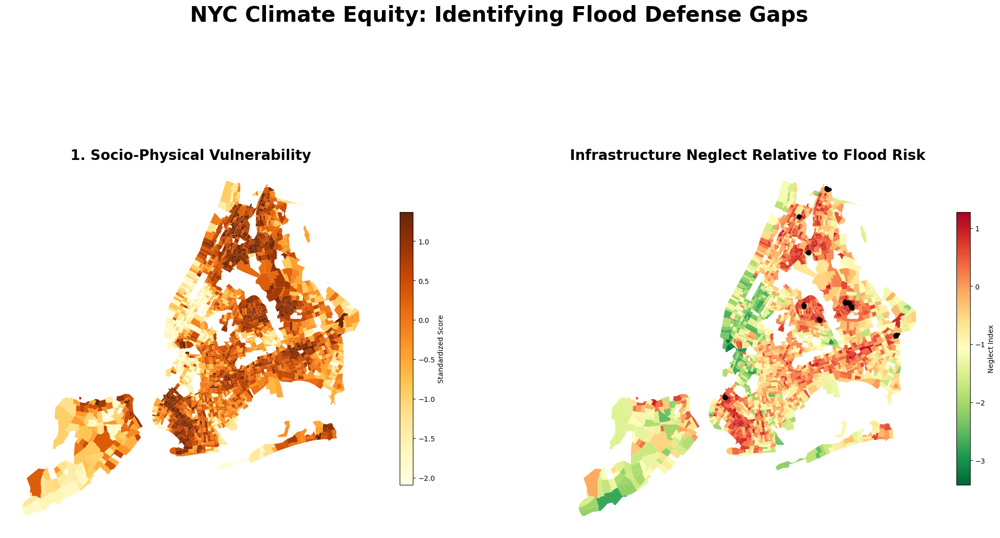

In [ ]:
import matplotlib.pyplot as plt

# Prepare Top 10 for highlighting (no text labels)
top_10_priority = final_analysis.sort_values('Neglect_Score', ascending=False).head(10).copy()
top_10_priority['centroid'] = top_10_priority.geometry.centroid

# Setup Plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(26, 14))
# MAP 1: VULNERABILITY
final_analysis.plot(column='Weighted_Vulnerability', cmap='YlOrBr', ax=ax1,
                    legend=True, legend_kwds={'shrink': 0.5, 'label': 'Standardized Score'})
ax1.set_title("1. Socio-Physical Vulnerability", fontsize=20, fontweight='bold')
ax1.axis('off')
# MAP 2: NEGLECT INDEX
final_analysis.plot(column='Neglect_Score', cmap='RdYlGn_r', ax=ax2,
                    legend=True, legend_kwds={'shrink': 0.5, 'label': 'Neglect Index'})

# Bold Black Outlines for the Top 10
top_10_priority.boundary.plot(ax=ax2, color='black', linewidth=3, label='Priority Tracts')

# Add a small black dot at the center of each to act as a "target"
top_10_priority['centroid'].plot(ax=ax2, marker='o', color='black', markersize=40)

# Keep the HUNTS POINT label as a general geographic anchor only
ax2.set_title("Infrastructure Neglect Relative to Flood Risk", fontsize=20, fontweight='bold')
ax2.axis('off')

plt.suptitle("NYC Climate Equity: Identifying Flood Defense Gaps", fontsize=30, y=0.98, fontweight='black')
plt.savefig("Clean_Equity_Map.png", dpi=300, bbox_inches='tight')
plt.show()

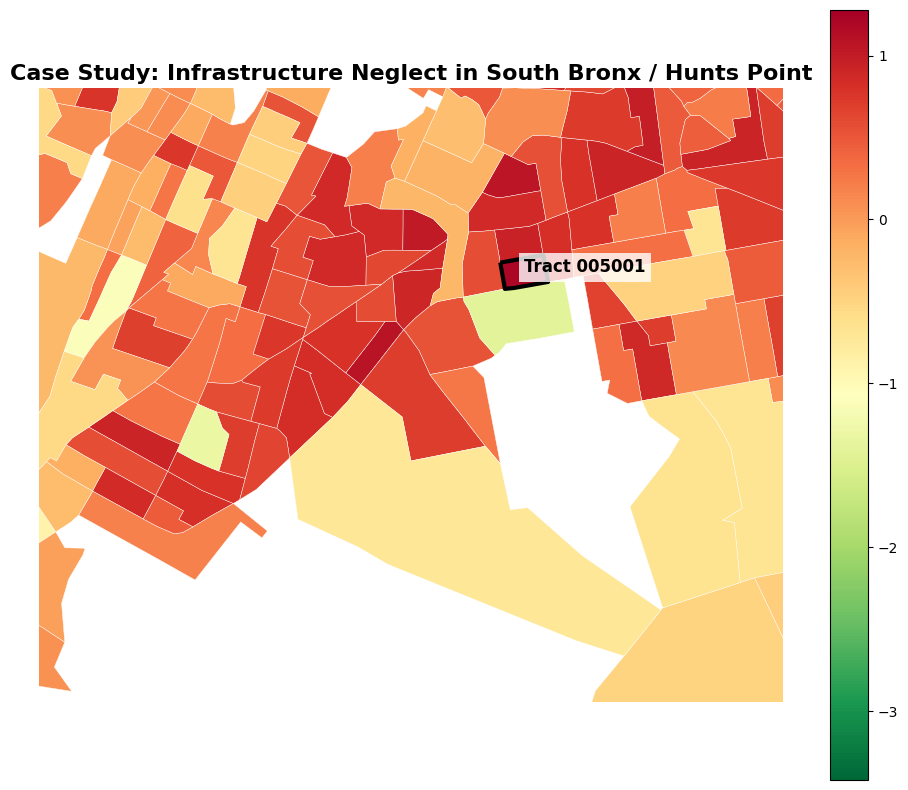

In [ ]:
# We extract the last 6 digits for the "Tract #" column to match standard Census notation
final_analysis['Tract_ID'] = final_analysis['GEOID'].str[-6:]
top_10_table = final_analysis.sort_values('Neglect_Score', ascending=False).head(10).copy()

fig, ax = plt.subplots(figsize=(12, 10))
final_analysis.plot(column='Neglect_Score', cmap='RdYlGn_r', ax=ax,
                    legend=True, edgecolor='white', linewidth=0.3)

# Bold the Top 10 Priority Zones
top_10_table.boundary.plot(ax=ax, color='black', linewidth=3)

# Define the Zoom window for South Bronx / Hunts Point
# Coordinates in EPSG:4326
ax.set_xlim(-73.93, -73.85)
ax.set_ylim(40.79, 40.84)

# Label the tracts inside this zoom window
for idx, row in top_10_table.iterrows():
    # Only label if it falls within our zoom coordinates
    if -73.93 < row.geometry.centroid.x < -73.85:
        ax.annotate(text=f"Tract {row['Tract_ID']}",
                     xy=(row.geometry.centroid.x, row.geometry.centroid.y),
                     fontsize=12, fontweight='bold', bbox=dict(facecolor='white', alpha=0.8, edgecolor='none'))

plt.title("Case Study: Infrastructure Neglect in South Bronx / Hunts Point", fontsize=16, fontweight='bold')
ax.axis('off')
plt.show()

In [ ]:
import folium

# Create a base map centered around NYC
m = folium.Map(location=[40.7128, -74.0060], zoom_start=10, tiles='CartoDB positron')

# Add choropleth layer for Neglect_Score
folium.Choropleth(
    geo_data=final_analysis.to_json(),
    name='Neglect Index',
    data=final_analysis,
    columns=['GEOID', 'Neglect_Score'],
    key_on='feature.properties.GEOID',
    fill_color='RdYlGn_r', # Red-Yellow-Green reversed, so high neglect is red
    fill_opacity=0.7,
    line_opacity=0.2,
    legend_name='Neglect Index Score',
    highlight=True
).add_to(m)

# Add tooltips for more detailed information
style_function = lambda x: {'fillColor': '#ffffff', 'color':'#000000', 'fillOpacity': 0.1, 'weight': 0.1}
highlight_function = lambda x: {'fillColor': '#000000', 'color':'#000000', 'fillOpacity': 0.50, 'weight': 0.1}

NIL = folium.features.GeoJson(
    final_analysis.to_json(),
    style_function=style_function,
    control=False,
    highlight_function=highlight_function,
    tooltip=folium.features.GeoJsonTooltip(
        fields=['GEOID', 'NTAName', 'Neglect_Score', 'Weighted_Vulnerability'],
        aliases=['GEOID:', 'Neighborhood:', 'Neglect Score:', 'Vulnerability Score:'],
        localize=True,
        sticky=False,
        labels=True,
        font_size='10pt',
        max_width='800px'
    )
)
m.add_child(NIL)
m.keep_in_front(NIL)

folium.LayerControl().add_to(m)

# Display the map
m

In [ ]:
# Save the Folium map to an HTML file
m.save('neglect_map.html')
print("Map saved to 'neglect_map.html'. You can download this file and open it in your web browser.")

Map saved to 'neglect_map.html'. You can download this file and open it in your web browser.


In [ ]:
from google.colab import files
files.download('neglect_map.html')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# In our new clean flow, 'final_analysis' is the master dataframe.

try:
    # If final_analysis exists, we are good to go.
    print(f"Master Data 'final_analysis' is ready with {len(final_analysis)} rows.")
except NameError:
    # If it's not found, we point it to master_gdf from Phase 1
    final_analysis = master_gdf.copy()
    print("re-synced master_gdf to final_analysis.")

# Ensure the Tract_ID (shorthand) is created
if 'Tract_ID' not in final_analysis.columns:
    final_analysis['Tract_ID'] = final_analysis['GEOID'].str[-6:]

Master Data 'final_analysis' is ready with 2209 rows.


In [ ]:
def get_research_label(row):
    """
    Handles missing neighborhood data gracefully to avoid "0, 0" labels.
    """
    # 1. Format the Tract number from GEOID (e.g., 36005000202 -> 2.02)
    tract_raw = str(row['GEOID'])[5:]
    tract_formatted = float(tract_raw) / 100

    # 2. Extract Neighborhood and Borough
    nta = row.get('NTAName')
    boro = row.get('BoroName')

    # 3. Check for invalid data (NaN, 0, or "0")
    # This is where the "0, 0" issue gets fixed
    is_valid_nta = pd.notnull(nta) and str(nta).strip() != '0' and str(nta).strip() != '0.0'
    is_valid_boro = pd.notnull(boro) and str(boro).strip() != '0' and str(boro).strip() != '0.0'

    if is_valid_nta and is_valid_boro:
        return f"{nta}, {boro} (Tract {tract_formatted})"
    elif is_valid_boro:
        # Fallback if we know the Borough but not the specific Neighborhood
        return f"{boro} Area (Tract {tract_formatted})"
    else:
        # Absolute fallback using the 11-digit GEOID to identify the Borough manually
        boro_map = {'005': 'Bronx', '047': 'Brooklyn', '061': 'Manhattan', '081': 'Queens', '085': 'Staten Island'}
        boro_code = str(row['GEOID'])[2:5]
        boro_name = boro_map.get(boro_code, "Unknown")
        return f"{boro_name} (Tract {tract_formatted})"

# Re-apply to the master dataframe
final_analysis['Area Name'] = final_analysis.apply(get_research_label, axis=1)

# --- Calculate project statistics per GEOID ---
project_stats = joined_data.groupby('GEOID').agg(
    Total_Projects=('maprojid', 'count'), # Count unique project IDs
    Proactive_Count=('nature', lambda x: (x == 'Preventative').sum()),
    Reactive_Count=('nature', lambda x: (x == 'Reconstructive').sum())
).reset_index()

# Calculate percentages, handling division by zero for tracts with no projects
project_stats['% Proactive'] = (project_stats['Proactive_Count'] / project_stats['Total_Projects']) * 100
project_stats['% Reactive'] = (project_stats['Reactive_Count'] / project_stats['Total_Projects']) * 100
project_stats.fillna(0, inplace=True)

# Merge these statistics into final_analysis
final_analysis = final_analysis.merge(
    project_stats[['GEOID', 'Total_Projects', '% Proactive', '% Reactive']],
    on='GEOID',
    how='left'
)

# Fill NaN values for tracts that had no projects after the merge (meaning they weren't in project_stats)
final_analysis[['Total_Projects', '% Proactive', '% Reactive']] = final_analysis[['Total_Projects', '% Proactive', '% Reactive']].fillna(0)

# --- RE-GENERATE BOTH TABLES ---

# 1. Top 10 NEGLECTED (Highest vulnerability, lowest infrastructure)
neglected_final = final_analysis.sort_values('Neglect_Score', ascending=False).head(10)

# 2. Top 10 PROTECTED (Highest infrastructure relative to risk)
protected_final = final_analysis.sort_values('Normalized_Protection', ascending=False).head(10)

def format_research_table(df, title, color_map):
    # Select columns - using your updated Area Name
    original_cols = ['Area Name', 'FSHRI', 'RPL_THEME1', 'Neglect_Score', 'Total_Projects', '% Proactive', '% Reactive']
    display_df = df[original_cols].copy()

    # Rename columns for professional display
    display_df.columns = ['Location', 'Risk (1-5)', 'SVI', 'Neglect Index', 'Projects', 'Proactive', 'Reactive']

    # Apply the "Academic Styling"
    styled = display_df.style.hide(axis='index') \
        .set_caption(f"<b style='font-size:16px; color:white; background-color:#222; padding:5px;'> {title} </b>") \
        .format({
            'Proactive': '{:,.1f}%',
            'Reactive': '{:,.1f}%',
            'Neglect Index': '{:,.2f}', # 2 decimals is standard for indices
            'SVI': '{:,.3f}',
            'Risk (1-5)': '{:,.1f}',
            'Projects': '{:,.0f}' # Round to whole number (no half-projects!)
        }) \
        .background_gradient(subset=['Neglect Index'], cmap=color_map) \
        .set_table_styles([
            {'selector': 'th', 'props': [('font-size', '11pt'), ('text-align', 'center'), ('color', '#ddd')]},
            {'selector': 'td', 'props': [('padding', '8px'), ('border-bottom', '1px solid #444')]}
        ])

    return styled

# Display the tables
display(format_research_table(neglected_final, "Census Tracts with Maximum Social Vulnerability (SVI) and Flood Susceptibility (FSHRI) Scores", "Reds"))
print("\n")
display(format_research_table(protected_final, "High Investment Benchmark Tracts", "Greens_r"))

Location,Risk (1-5),SVI,Neglect Index,Projects,Proactive,Reactive
"Murray Hill-Broadway Flushing, Queens (Tract 1163.02)",5.0,0.965,1.28,0,0.0%,0.0%
"Jackson Heights, Queens (Tract 327.0)",5.0,0.979,1.21,10,0.0%,0.0%
"Soundview-Bruckner-Bronx River, Bronx (Tract 50.01)",5.0,1.000,1.21,14,0.0%,0.0%
"Queens Village, Queens (Tract 564.0)",5.0,0.927,1.18,0,0.0%,0.0%
"Murray Hill-Broadway Flushing, Queens (Tract 1167.0)",5.0,0.919,1.16,0,0.0%,0.0%
"Corona, Queens (Tract 443.01)",5.0,0.999,1.13,25,0.0%,0.0%
"Sunset Park (West), Brooklyn (Tract 76.0)",5.0,0.981,1.12,13,0.0%,0.0%
"East Flushing, Queens (Tract 1191.0)",5.0,0.940,1.12,3,0.0%,0.0%
"Bedford Park, Bronx (Tract 403.03)",5.0,0.972,1.10,17,0.0%,0.0%
"Wakefield-Woodlawn, Bronx (Tract 442.0)",5.0,0.970,1.09,14,0.0%,0.0%


Location,Risk (1-5),SVI,Neglect Index,Projects,Proactive,Reactive
"Financial District-Battery Park City, Manhattan (Tract 15.01)",2.0,0.295,-3.11,417,0.0%,18.2%
"Financial District-Battery Park City, Manhattan (Tract 15.02)",1.0,0.203,-3.15,312,0.0%,21.8%
"Financial District-Battery Park City, Manhattan (Tract 7.0)",1.0,0.041,-3.42,273,0.0%,24.2%
"Sheepshead Bay-Manhattan Beach-Gerritsen Beach, Brooklyn (Tract 608.0)",4.0,0.644,-1.12,253,0.0%,24.9%
Manhattan (Tract 2.02),4.0,0.823,-0.65,207,3.4%,37.7%
"Concourse-Concourse Village, Bronx (Tract 195.0)",5.0,0.948,-0.11,287,0.7%,7.3%
"Tompkinsville-Stapleton-Clifton-Fox Hills, Staten Island (Tract 21.0)",4.0,0.760,-0.81,269,0.0%,16.7%
"St. George-New Brighton, Staten Island (Tract 3.0)",4.0,0.711,-0.92,285,0.0%,8.4%
"Tribeca-Civic Center, Manhattan (Tract 31.0)",1.0,0.431,-2.28,279,0.0%,10.4%
"East Harlem (North), Manhattan (Tract 242.0)",1.0,0.959,-0.89,251,0.0%,20.7%


In [ ]:
import pandas as pd

# Load and rename your dataset
df = final_analysis.rename(columns={
    'Area Name': 'Location',
    'FSHRI': 'Risk (1-5)',
    'RPL_THEME1': 'SVI',
    'Neglect_Score': 'Neglect Index',
    'Total_Projects': 'Projects',
    '% Proactive': 'Proactive',
    '% Reactive': 'Reactive'
}).copy()

# Find the exact Hunts Point entries
search_results = df[df['Location'].str.contains("Hunts Point", case=False, na=False)]

print("--- Search Results for 'Hunts Point' ---")
if not search_results.empty:
    print(search_results[['Location', 'Risk (1-5)', 'SVI', 'Neglect Index']])

    # Automatically pick the one with the highest Neglect Index
    # target_tract = search_results.sort_values(by='Neglect Index', ascending=False).iloc[0]['Location']

    # OR specific tract choice
    target_tract = "Soundview-Bruckner-Bronx River, Bronx (Tract 50.01)"
else:
    print("No tracts found with 'Hunts Point' in the name.")
    target_tract = "Soundview-Bruckner-Bronx River, Bronx (Tract 50.01)"

# 1. Isolate the stats for your chosen tract
hp_stats = df[df['Location'] == target_tract]

# 2. Display the Core "Neglect" Metrics
print(f"\n--- Statistics for {target_tract} ---")
if not hp_stats.empty:
    print(f"Physical Risk Score: {hp_stats['Risk (1-5)'].values[0]}")
    print(f"Social Vulnerability (SVI): {hp_stats['SVI'].values[0]}")
    print(f"Neglect Index Score: {hp_stats['Neglect Index'].values[0]}")
    print(f"Total Projects in 200m Buffer: {hp_stats['Projects'].values[0]}")
    print(f"Proactive Investment Rate: {hp_stats['Proactive'].values[0]}%")
    print(f"Reactive Investment Rate: {hp_stats['Reactive'].values[0]}%")
else:
    print(f"Location '{target_tract}' not found. Check the Search Results list above.")

# 3. Comparative Analysis
city_avg_neglect = df['Neglect Index'].mean()
print(f"\nCity-wide Average Neglect Index: {city_avg_neglect:.2f}")

if not hp_stats.empty:
    gap = hp_stats['Neglect Index'].values[0] - city_avg_neglect
    print(f"Hunts Point Neglect Gap: {gap:.2f} points above average.")

--- Search Results for 'Hunts Point' ---
                               Location  Risk (1-5)     SVI  Neglect Index
166     Hunts Point, Bronx (Tract 89.0)         5.0  0.9876       1.084024
506   Hunts Point, Bronx (Tract 115.02)         4.0  0.9069       0.541046
557    Hunts Point, Bronx (Tract 93.01)         4.0  0.9645       0.697644
1730  Hunts Point, Bronx (Tract 117.01)         2.0  0.9639       0.255074
2207   Hunts Point, Bronx (Tract 93.02)         3.0  0.6959      -0.706489

--- Statistics for Soundview-Bruckner-Bronx River, Bronx (Tract 50.01) ---
Physical Risk Score: 5.0
Social Vulnerability (SVI): 0.9998
Neglect Index Score: 1.2076589032073193
Total Projects in 200m Buffer: 14
Proactive Investment Rate: 0.0%
Reactive Investment Rate: 0.0%

City-wide Average Neglect Index: -0.46
Hunts Point Neglect Gap: 1.67 points above average.
